# Server response time alerts with CTSM 1.5

Forecast the next 128 minutes of server latency and flag sustained exceedances of P90 and P50 thresholds.

**Setup** · Use a Jupyter kernel with PyTorch, NumPy, pandas and Matplotlib.
Start from within the CTSM checkout and place the released CTSM 1.5 weights at
`checkpoints/model.safetensors` relative to the checkout root,
or set `CTSM_CHECKPOINT` to its path before starting Jupyter.

**Data** · The repository’s [`server_responsetime.csv`](../../1.0-preview/sample_data/server_responsetime.csv) contains 9,999 timestamped average response times in milliseconds.

In [1]:
from pathlib import Path
import os
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Support kernels started from the checkout root or the notebook directory.
working_dir = Path.cwd().resolve()
root = next(
    (
        candidate
        for candidate in (working_dir, *working_dir.parents)
        if (candidate / "ctsm_1p5" / "modeling" / "__init__.py").is_file()
    ),
    None,
)
if root is None:
    raise FileNotFoundError("Start the notebook from within the CTSM 1.5 checkout.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from ctsm_1p5.modeling import load_model

checkpoint = Path(
    os.environ.get("CTSM_CHECKPOINT", "checkpoints/model.safetensors")
).expanduser()
if not checkpoint.is_absolute():
    checkpoint = root / checkpoint
if not checkpoint.is_file():
    raise FileNotFoundError(
        f"CTSM 1.5 weights not found at {checkpoint}. Set CTSM_CHECKPOINT to the checkpoint path."
    )

HORIZON = 128
model = load_model(checkpoint)

## Load and regularize the observations

The source timestamps are slightly more than a minute apart. Bin readings at
one-minute intervals in the source’s Pacific local time. Leave missing minutes
in the history for CTSM’s missing-value handling.

In [2]:
samples = pd.read_csv(root / "1.0-preview" / "sample_data" / "server_responsetime.csv")
clock = (
    pd.to_datetime(samples["_time"], utc=True)
    .dt.tz_convert("America/Los_Angeles")
    .dt.tz_localize(None)
)
series = (
    pd.Series(samples["rta"].to_numpy(dtype=np.float32), index=clock)
    .sort_index()
    .resample("1min")
    .mean()
)

## Forecast response time

The plotted P10–P90 interval and P50 point forecast come from the same model call.
The example rules flag P90 above 6.5 ms for five minutes or P50 above 6.0 ms for
ten minutes. These thresholds illustrate how to translate forecasts into alert rules.

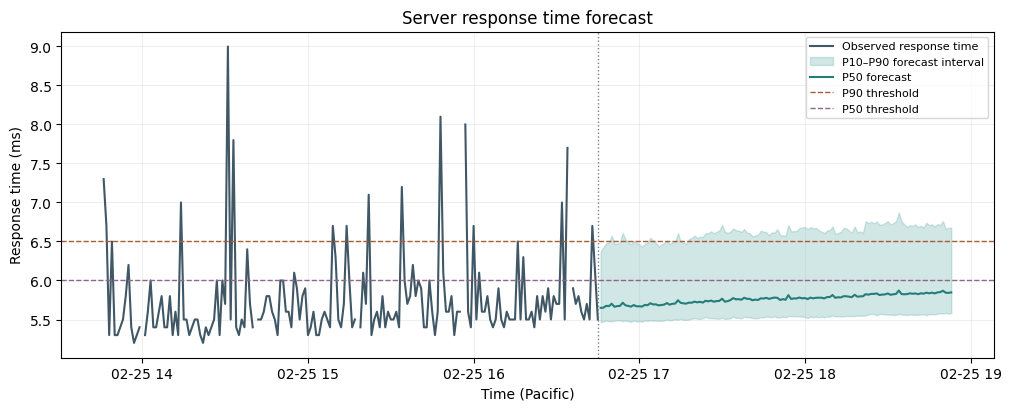

In [3]:
rules = [
    ("P90", "0.9", 6.5, 5),
    ("P50", "0.5", 6.0, 10),
]

quantiles = model.forecast(
    series.to_numpy(), timestamps=series.index.to_numpy(), horizon_len=HORIZON,
)[0]["quantiles"]
future_clock = pd.date_range(
    series.index[-1] + pd.Timedelta(minutes=1), periods=HORIZON, freq="1min",
)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
recent = series.tail(180)
ax.plot(recent.index, recent, color="#405766", label="Observed response time")
ax.fill_between(
    future_clock, quantiles["0.1"], quantiles["0.9"],
    color="#49A19D", alpha=0.25, label="P10–P90 forecast interval",
)
ax.plot(future_clock, quantiles["0.5"], color="#247D77", label="P50 forecast")
for (label, _, threshold, _), color in zip(rules, ("#A95B36", "#91658A")):
    ax.axhline(threshold, color=color, linestyle="--", linewidth=1, label=f"{label} threshold")
ax.axvline(series.index[-1], color="#72828B", linestyle=":", linewidth=1)
ax.set(title="Server response time forecast", xlabel="Time (Pacific)", ylabel="Response time (ms)")
ax.grid(alpha=0.2)
ax.legend(loc="best", fontsize=8)
display(fig)
plt.close(fig)

## Find the first sustained forecast exceedance

Show each rule’s first predicted breach window. A rule without a complete run above
its threshold produces no alert.

In [4]:
alerts = []
for label, key, threshold, minutes in rules:
    exceeds = quantiles[key] > threshold
    complete_windows = np.lib.stride_tricks.sliding_window_view(exceeds, minutes)
    matches = np.flatnonzero(complete_windows.all(axis=1))
    if len(matches):
        first = matches[0]
        alerts.append({
            "Quantile": label,
            "Threshold (ms)": threshold,
            "Consecutive minutes": minutes,
            "Starts (Pacific)": future_clock[first],
            "Window ends (Pacific)": future_clock[first + minutes - 1],
        })

if alerts:
    display(pd.DataFrame(alerts))
else:
    print("No sustained forecast exceedances in the next 128 minutes.")

,Quantile,Threshold (ms),Consecutive minutes,Starts (Pacific),Window ends (Pacific)
0,P90,6.5,5,2015-02-25 17:18:00,2015-02-25 17:22:00
